# Ejercicio — Búsqueda en Anchura (BFS)
## Fundamentos de Inteligencia Artificial

### Objetivo
Aplicar y modificar un programa de **Búsqueda en Anchura (BFS)** sobre un problema sencillo.

En esta práctica:
- usarás un grafo ya construido;
- ejecutarás BFS;
- observarás la cola y el orden de visita;
- cambiarás el problema;
- modificarás parte del código y volverás a probarlo.

> Recuerda: BFS explora el espacio de búsqueda **por niveles** y utiliza una **cola FIFO**.


## Problema base: Robot de mensajería en un edificio

Un robot debe llevar un documento desde **Entrada** hasta **Archivo**.

Zonas:
Entrada, Recepción, Sala, Oficina A, Oficina B, Laboratorio y Archivo.

Conexiones:
- Entrada ↔ Recepción
- Recepción ↔ Sala
- Recepción ↔ Oficina A
- Sala ↔ Oficina B
- Oficina A ↔ Laboratorio
- Oficina B ↔ Archivo
- Laboratorio ↔ Archivo

**Inicio:** Entrada  
**Meta:** Archivo


In [1]:
from collections import deque
import networkx as nx
import matplotlib.pyplot as plt


In [2]:
grafo = {
    "Entrada": ["Recepción"],
    "Recepción": ["Entrada", "Sala", "Oficina A"],
    "Sala": ["Recepción", "Oficina B"],
    "Oficina A": ["Recepción", "Laboratorio"],
    "Oficina B": ["Sala", "Archivo"],
    "Laboratorio": ["Oficina A", "Archivo"],
    "Archivo": ["Oficina B", "Laboratorio"]
}

inicio = "Entrada"
meta = "Archivo"


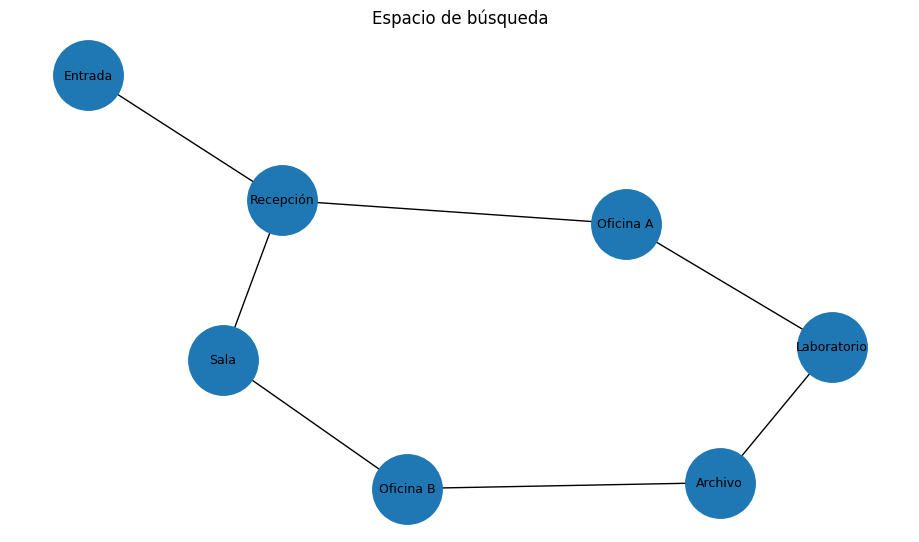

In [3]:
G = nx.Graph()

for estado, vecinos in grafo.items():
    G.add_node(estado)
    for vecino in vecinos:
        G.add_edge(estado, vecino)

plt.figure(figsize=(9,5))
nx.draw(G, with_labels=True, node_size=2500, font_size=9)
plt.title("Espacio de búsqueda")
plt.show()


## Función BFS

La cola almacena pares `(nodo, camino)`. Así, el algoritmo conserva el estado que va a visitar y el camino seguido para llegar a él.


In [4]:
def bfs(grafo, inicio, meta, mostrar=True):
    cola = deque([(inicio, [inicio])])
    visitados = set()
    orden = []

    while cola:
        if mostrar:
            print("Cola:", [n for n, _ in cola])

        nodo, camino = cola.popleft()

        if nodo in visitados:
            continue

        visitados.add(nodo)
        orden.append(nodo)

        if mostrar:
            print("Visitando:", nodo)

        if nodo == meta:
            return orden, camino

        for vecino in grafo.get(nodo, []):
            if vecino not in visitados:
                cola.append((vecino, camino + [vecino]))

    return orden, None


In [5]:
# Ejecutamos la simulación para comprobar tus predicciones
orden_bfs, camino_bfs = bfs(grafo, inicio, meta)
print("\nOrden de visita final:", orden_bfs)
print("Camino más corto encontrado:", camino_bfs)

Cola: ['Entrada']
Visitando: Entrada
Cola: ['Recepción']
Visitando: Recepción
Cola: ['Sala', 'Oficina A']
Visitando: Sala
Cola: ['Oficina A', 'Oficina B']
Visitando: Oficina A
Cola: ['Oficina B', 'Laboratorio']
Visitando: Oficina B
Cola: ['Laboratorio', 'Archivo']
Visitando: Laboratorio
Cola: ['Archivo', 'Archivo']
Visitando: Archivo

Orden de visita final: ['Entrada', 'Recepción', 'Sala', 'Oficina A', 'Oficina B', 'Laboratorio', 'Archivo']
Camino más corto encontrado: ['Entrada', 'Recepción', 'Sala', 'Oficina B', 'Archivo']


## Ejecución inicial

Antes de ejecutar, predice:
1. ¿Qué nodo se visitará primero? Nodo:entrada
2. ¿Qué nodos entrarán después a la cola?  recepcion
3. ¿Qué camino crees que encontrará BFS? ['Entrada', 'Recepción', 'Sala', 'Oficina B', 'Archivo']


In [6]:
orden_bfs, camino_bfs = bfs(grafo, inicio, meta)

print("\nOrden BFS:", orden_bfs)
print("Camino BFS:", camino_bfs)


Cola: ['Entrada']
Visitando: Entrada
Cola: ['Recepción']
Visitando: Recepción
Cola: ['Sala', 'Oficina A']
Visitando: Sala
Cola: ['Oficina A', 'Oficina B']
Visitando: Oficina A
Cola: ['Oficina B', 'Laboratorio']
Visitando: Oficina B
Cola: ['Laboratorio', 'Archivo']
Visitando: Laboratorio
Cola: ['Archivo', 'Archivo']
Visitando: Archivo

Orden BFS: ['Entrada', 'Recepción', 'Sala', 'Oficina A', 'Oficina B', 'Laboratorio', 'Archivo']
Camino BFS: ['Entrada', 'Recepción', 'Sala', 'Oficina B', 'Archivo']


## Parte 1 — Primera modificación

Cambia el problema:

- agrega un nuevo estado llamado **Pasillo C**;
- conecta `Sala` con `Pasillo C`;
- conecta `Pasillo C` con `Archivo`;
- cambia la meta de `Archivo` a `Laboratorio`.

Debes modificar el diccionario, la meta y volver a ejecutar BFS.


In [7]:
# MODIFICA ESTE BLOQUE

grafo_modificado = {
    "Entrada": ["Recepción"],
    "Recepción": ["Entrada", "Sala", "Oficina A"],
    "Sala": ["Recepción", "Oficina B"],
    "Oficina A": ["Recepción", "Laboratorio"],
    "Oficina B": ["Sala", "Archivo"],
    "Laboratorio": ["Oficina A", "Archivo"],
    "Archivo": ["Oficina B", "Laboratorio"],
    "Pasillo C": ["Archivo"]

    # Agrega Pasillo C y modifica las conexiones necesarias
}

inicio_modificado = "Entrada"
meta_modificada = "Laboratorio"  # Cambiar a Laboratorio


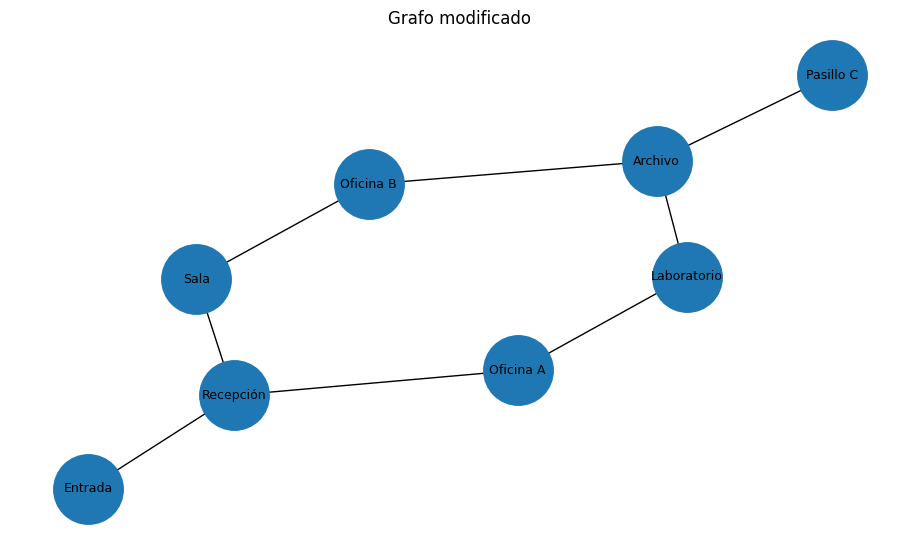

Cola: ['Entrada']
Visitando: Entrada
Cola: ['Recepción']
Visitando: Recepción
Cola: ['Sala', 'Oficina A']
Visitando: Sala
Cola: ['Oficina A', 'Oficina B']
Visitando: Oficina A
Cola: ['Oficina B', 'Laboratorio']
Visitando: Oficina B
Cola: ['Laboratorio', 'Archivo']
Visitando: Laboratorio

Orden BFS: ['Entrada', 'Recepción', 'Sala', 'Oficina A', 'Oficina B', 'Laboratorio']
Camino BFS: ['Entrada', 'Recepción', 'Oficina A', 'Laboratorio']


In [8]:
G2 = nx.Graph()

for estado, vecinos in grafo_modificado.items():
    G2.add_node(estado)
    for vecino in vecinos:
        G2.add_edge(estado, vecino)

plt.figure(figsize=(9,5))
nx.draw(G2, with_labels=True, node_size=2500, font_size=9)
plt.title("Grafo modificado")
plt.show()

orden, camino = bfs(grafo_modificado, inicio_modificado, meta_modificada)

print("\nOrden BFS:", orden)
print("Camino BFS:", camino)


### Responde

1. ¿Cambió el orden de visita?si
2. ¿Cambió el camino encontrado?si
3. ¿Por qué BFS visita primero ciertos nodos?visita primero los que estan mas cerca del nodo inicial
4. ¿Qué significa que BFS explore por niveles?Significa que el algoritmo realiza una búsqueda horizontal


## Parte 2 — Segunda modificación

Ahora **Oficina A queda cerrada**.

- conserva `Oficina A` como estado;
- elimina sus conexiones;
- elimina también las referencias hacia `Oficina A` desde otros estados;
- cambia la meta nuevamente a `Archivo`.

Ejecuta otra vez BFS.


In [9]:
# ESCRIBE AQUÍ EL NUEVO GRAFO

grafo_sin_oficinaA = {
 "Entrada": ["Recepción"],
    "Recepción": ["Entrada", "Sala"],
    "Sala": ["Recepción", "Oficina B"],
    "Oficina A": [],
    "Oficina B": ["Sala", "Archivo"],
    "Laboratorio": ["Oficina A", "Archivo"],
    "Archivo": ["Oficina B", "Laboratorio"],
    "Pasillo C": ["Archivo"]
}




inicio_2 = "Entrada"
meta_2 = "Archivo"


In [10]:
orden_2, camino_2 = bfs(grafo_sin_oficinaA, inicio_2, meta_2)

print("\nOrden BFS:", orden_2)
print("Camino BFS:", camino_2)


Cola: ['Entrada']
Visitando: Entrada
Cola: ['Recepción']
Visitando: Recepción
Cola: ['Sala']
Visitando: Sala
Cola: ['Oficina B']
Visitando: Oficina B
Cola: ['Archivo']
Visitando: Archivo

Orden BFS: ['Entrada', 'Recepción', 'Sala', 'Oficina B', 'Archivo']
Camino BFS: ['Entrada', 'Recepción', 'Sala', 'Oficina B', 'Archivo']


## Parte 3 — Modificación del programa

Ahora modifica el algoritmo.

Haz que además de mostrar el nodo visitado, indique cuántos nodos se han visitado hasta ese momento.

Ejemplo:

`Visitando: Recepción | Total visitados: 2`


In [11]:
def bfs_modificado(grafo, inicio, meta, mostrar=True):
    cola = deque([(inicio, [inicio])])
    visitados = set()
    orden = []

    while cola:
        if mostrar:
            print("Cola:", [n for n, _ in cola])

        nodo, camino = cola.popleft()

        if nodo in visitados:
            continue

        visitados.add(nodo)
        orden.append(nodo)

        if mostrar:
            # MODIFICA ESTA LÍNEA
            print("Visitando:", nodo, "| Total visitados:", len(visitados))

        if nodo == meta:
            return orden, camino

        for vecino in grafo.get(nodo, []):
            if vecino not in visitados:
                cola.append((vecino, camino + [vecino]))

    return orden, None

In [12]:
orden_3, camino_3 = bfs_modificado(grafo, inicio, meta)

print("\nOrden BFS:", orden_3)
print("Camino BFS:", camino_3)


Cola: ['Entrada']
Visitando: Entrada | Total visitados: 1
Cola: ['Recepción']
Visitando: Recepción | Total visitados: 2
Cola: ['Sala', 'Oficina A']
Visitando: Sala | Total visitados: 3
Cola: ['Oficina A', 'Oficina B']
Visitando: Oficina A | Total visitados: 4
Cola: ['Oficina B', 'Laboratorio']
Visitando: Oficina B | Total visitados: 5
Cola: ['Laboratorio', 'Archivo']
Visitando: Laboratorio | Total visitados: 6
Cola: ['Archivo', 'Archivo']
Visitando: Archivo | Total visitados: 7

Orden BFS: ['Entrada', 'Recepción', 'Sala', 'Oficina A', 'Oficina B', 'Laboratorio', 'Archivo']
Camino BFS: ['Entrada', 'Recepción', 'Sala', 'Oficina B', 'Archivo']


## Conclusión

Responde en 5 a 8 líneas:

- ¿Qué función cumple la cola en BFS? Almacena de manera ordenada los nodos que han sido descubiertos pero que aún no han sido explorados, asegurando que se procesen secuencialmente.
- ¿Qué significa FIFO? first in, first out
- ¿Por qué BFS se considera búsqueda ciega? Porque no utiliza información del dominio ni estimaciones sobre la distancia restante a la meta para guiar la búsqueda (no tiene heurística).
- ¿Qué sucede con el recorrido cuando cambia el grafo?Se reestructura dinámicamente según las conexiones disponibles, pudiendo cambiar el orden de visitas, la profundidad o incluso no encontrar una ruta si hay desconexiones.
- ¿Qué ventaja observaste en BFS para encontrar rutas con pocos pasos?
 Garantiza hallar siempre la ruta más corta en términos de número de aristas/enlaces desde el origen.
